## How to Run

Download the C-MAPSS FD001 dataset from the NASA Prognostics Data Repository and place the three files (`train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt`) inside a folder named `fd001/` next to this notebook.

# Remaining Useful Life (RUL) Prediction for Aircraft Engines

**Dataset:** NASA C-MAPSS (FD001 subset)

This notebook uses sensor data from turbofan engines to predict each engine's Remaining Useful Life (RUL), i.e. the number of cycles left until the engine fails. The goal is to compare several models and see how much feature engineering contributes to accuracy.

## Project Roadmap

1. Libraries and data loading
2. Preprocessing (dropping uninformative columns, building the RUL label, preparing the test data)
3. Baseline models: Linear Regression, Random Forest, and XGBoost (plus GroupKFold cross-validation)
4. Feature importance in the baseline model
5. Feature engineering and retraining XGBoost
6. Visual analysis of the results
7. Conclusion

## Evaluation Metrics

Two metrics are reported, both in cycles; for both, lower is better:

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2} \qquad MAE = \frac{1}{n}\sum_{i=1}^{n}\left|\hat{y}_i - y_i\right|$$

- **RMSE** penalizes large errors more heavily.
- **MAE** is the mean absolute error and is easier to interpret.

## 1. Libraries and Data Loading

The data consists of three files:

- `train_FD001.txt`: full run-to-failure trajectories of the training engines
- `test_FD001.txt`: engine trajectories that were cut off before failure
- `RUL_FD001.txt`: the true RUL of each test engine

Each row is one flight cycle and contains the engine ID, the cycle number, three operational settings, and 21 sensor readings.

### 1.1 Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

# Fix the global random seed for reproducibility
np.random.seed(42)

### 1.2 Reading the Files

The training, test, and true-RUL files are read, and completely empty columns are dropped. The training data contains 20631 rows (cycles) and 26 columns.

In [ ]:
columns = [
    'unit_number', 'time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3',
    'T2', 'T24', 'T30', 'T50', 'P2', 'P15', 'P30', 'Nf', 'Nc', 'epr', 
    'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'farB', 'htBleed', 'Nf_dmd', 
    'PCNfR_dmd', 'W31', 'W32'
]

path_train = '../fd001/train_FD001.txt'
path_test = '../fd001/test_FD001.txt'
path_rul = '../fd001/RUL_FD001.txt'

df_train = pd.read_csv(path_train, sep=r'\s+', header=None, names=columns)
df_test = pd.read_csv(path_test, sep=r'\s+', header=None, names=columns)
rul_truth = pd.read_csv(path_rul, sep=r'\s+', header=None, names=['RUL'])

df_train.dropna(axis=1, how='all', inplace=True)
df_test.dropna(axis=1, how='all', inplace=True)


df_train

## 2. Preprocessing

### 2.1 Identifying Uninformative Columns

A column that is constant across the entire training set carries no information for prediction. These columns, together with the identifier columns (`unit_number` and `time_in_cycles`), are collected in the list `constant_cols` so they can be dropped later.

In [ ]:
constant_cols = ['unit_number', 'time_in_cycles']

for col in df_train.columns:
    if df_train[col].min() == df_train[col].max():
        constant_cols.append(col)

constant_cols

**Result:** seven constant columns were found: `op_setting_3`, `T2`, `P2`, `epr`, `farB`, `Nf_dmd`, and `PCNfR_dmd`.

### 2.2 Building the RUL Label

For each training engine, the RUL at every cycle equals "the engine's last cycle − the current cycle". The RUL is then clipped at an upper bound of 125, because early in an engine's life the sensors show no reliable sign of degradation yet, and this is a common practice for this problem.

In [ ]:
df = df_train.copy()
max_cycles = df.groupby('unit_number')['time_in_cycles'].transform('max')
df['RUL'] = max_cycles - df['time_in_cycles']
df['RUL'] = df['RUL'].clip(upper=125)
df

### 2.3 Dropping Uninformative Columns and Separating Inputs from the Target

After dropping `constant_cols`, 17 features (`X_train`) and the RUL target column (`y_train`) remain.

In [ ]:
df = df.drop(columns = constant_cols)
df

In [6]:
X_train = df.drop(columns = 'RUL')
y_train = df['RUL']

### 2.4 Preparing the Test Data

For each test engine, only the last recorded cycle is kept, because the true RUL (`rul_truth`) is given for exactly that moment. The result is one row for each of the 100 test engines.

In [ ]:
df_test_last = df_test.groupby('unit_number').last().reset_index()
df_test_last = df_test_last.drop(columns = constant_cols)
df_test_last

## 3. Baseline Models

We train three models of increasing complexity on the raw features to get a reference point for measuring the effect of feature engineering. All models are evaluated on the last cycle of the test engines using RMSE and MAE.

### 3.1 Linear Regression with Polynomial Features

The features are first expanded with `PolynomialFeatures` (degree 2), then standardized, and finally fed to a linear regression.

In [ ]:
lr_model = Pipeline([
    ('poly' , PolynomialFeatures(degree = 2, include_bias = False)),
    ('scale' , StandardScaler()),
    ('reg' , LinearRegression())
])
lr_model.fit(X_train, y_train)

In [ ]:
y_pred_lr = lr_model.predict(df_test_last)
y_pred_lr

In [10]:
rmse_lr = np.sqrt(mean_squared_error(rul_truth, y_pred_lr))
mae_lr = mean_absolute_error(rul_truth, y_pred_lr)

print(f"RMSE: {rmse_lr:.2f}")
print(f"MAE: {mae_lr:.2f}")

RMSE: 20.09
MAE: 15.41


**Result of 3.1:** RMSE is 20.09 and MAE is 15.41.

### 3.2 Random Forest

A random forest with 200 trees that can learn nonlinear relationships between sensors.

In [ ]:
rf_model = Pipeline(steps = [
    ('rf' , RandomForestRegressor(n_estimators = 200, random_state = 42, n_jobs = -1))
])
rf_model.fit(X_train , y_train)

In [ ]:
y_pred_rf = rf_model.predict(df_test_last)
y_pred_rf

In [13]:
rmse_rf = np.sqrt(mean_squared_error(rul_truth, y_pred_rf))
mae_rf = mean_absolute_error(rul_truth, y_pred_rf)

print(f"RMSE: {rmse_rf:.2f}")
print(f"MAE: {mae_rf:.2f}")

RMSE: 18.05
MAE: 13.06


**Result of 3.2:** RMSE is 18.05 and MAE is 13.06.

### 3.3 XGBoost

A gradient boosting model with a learning rate of 0.02 and 700 trees.

In [ ]:
xgb_model = XGBRegressor(
    learning_rate = 0.02,
    n_estimators = 700,
    random_state = 42,
    n_jobs = -1
)
xgb_model.fit(X_train, y_train)

In [ ]:
y_pred_xgb = xgb_model.predict(df_test_last)
y_pred_xgb

In [16]:
rmse_xgb = np.sqrt(mean_squared_error(rul_truth, y_pred_xgb))
mae_xgb = mean_absolute_error(rul_truth, y_pred_xgb)

print(f"RMSE: {rmse_xgb:.2f}")
print(f"MAE: {mae_xgb:.2f}")

RMSE: 17.65
MAE: 12.77


**Result of 3.3:** RMSE is 17.65 and MAE is 12.77.

### 3.4 Summary of the Baseline Models

| Model | RMSE | MAE |
|:---|:---:|:---:|
| Linear Regression (degree-2 polynomial) | 20.09 | 15.41 |
| Random Forest | 18.05 | 13.06 |
| XGBoost | **17.65** | **12.77** |

The tree-based models beat linear regression, but the gap between Random Forest and XGBoost is small (about 0.4 in RMSE). In other words, simply switching the algorithm does not make a big difference; further improvement has to come from the features themselves.

### 3.5. Cross-Validation with GroupKFold

The results above come from a single train/test split. To check how stable the baseline models are, we also evaluate them with 5-fold cross-validation on the training engines.

**Why GroupKFold?** If we split the data into train and validation sets at random, the cycles of one engine end up in both parts, and the model effectively memorizes the engine. With GroupKFold, the validation engines are completely separate from the training engines, so the evaluation is more realistic.

The groups are the engine IDs (`unit_number`). In every fold the model is copied with `sklearn.base.clone`, so each fold starts from an untrained model. RMSE and MAE are computed on the held-out engines and then summarized as mean and standard deviation over the 5 folds.

> Note: the cross-validation scores use every cycle of the validation engines, while the test-set scores above use only the last cycle of each test engine. The two sets of numbers are therefore not directly comparable; use the cross-validation table to compare the models with each other and to judge how stable they are.

In [17]:
# Keep a copy of the engine IDs. df_train still holds 'unit_number' (it was dropped only
# from the working copy `df`), and its row order matches X_train / y_train.
groups = df_train['unit_number'].copy()
assert len(groups) == len(X_train) == len(y_train)

cv_models = {
    'Linear Regression (Poly-2)': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
}

gkf = GroupKFold(n_splits=5)
cv_rows = []

for name, base_model in cv_models.items():
    rmse_folds, mae_folds = [], []

    for train_idx, val_idx in gkf.split(X_train, y_train, groups=groups):
        # No engine may appear in both the training and the validation part
        assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[val_idx])

        fold_model = clone(base_model)  # fresh, unfitted copy for every fold
        fold_model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        y_val_pred = fold_model.predict(X_train.iloc[val_idx])

        rmse_folds.append(np.sqrt(mean_squared_error(y_train.iloc[val_idx], y_val_pred)))
        mae_folds.append(mean_absolute_error(y_train.iloc[val_idx], y_val_pred))

    cv_rows.append({
        'Model': name,
        'RMSE_mean': np.mean(rmse_folds),
        'RMSE_std': np.std(rmse_folds),
        'MAE_mean': np.mean(mae_folds),
        'MAE_std': np.std(mae_folds),
    })

cv_results = pd.DataFrame(cv_rows).round(2)
cv_results

,Model,RMSE_mean,RMSE_std,MAE_mean,MAE_std
0,Linear Regression (Poly-2),19.69,1.29,15.56,1.04
1,Random Forest,18.62,1.34,13.68,1.07
2,XGBoost,18.58,1.42,13.43,1.11


## 4. Feature Importance in the Baseline Model

To understand which features the baseline XGBoost relies on, we review the ten most important features.

In [18]:
importance_base = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_base.head(10))

    feature  importance
9      Ps30    0.523730
4       T50    0.128947
8        Nc    0.096410
10      phi    0.059476
6       P30    0.030947
13      BPR    0.025446
12      NRc    0.024356
14  htBleed    0.021882
15      W31    0.018838
11      NRf    0.017065


**Interpretation:** The `Ps30` sensor alone accounts for about 52% of the importance, and the top three features (`Ps30`, `T50`, and `Nc`) together account for about 75%. So the baseline model relies mainly on the instantaneous values of a few sensors. An instantaneous sensor value is noisy and does not show the engine's degradation trend over time; this motivates building time-dependent features.

## 5. Feature Engineering

### 5.1 Building Temporal Features

For each of the 16 columns (sensors and operational settings), and separately for each engine, three features are built:

- **`_rolling_5`**: 5-cycle moving average to reduce noise
- **`_diff_10`**: change relative to 10 cycles earlier, as the rate of change
- **`_deviation`**: difference between the current value and the mean of the engine's first 10 cycles, as the amount of drift from the initial state

In total, 48 new features are added to the 17 original ones.

In [19]:
sensors = ['T24', 'T30', 'T50', 'P30', 'Ps30', 
           'Nf', 'Nc', 'NRf', 'NRc', 'phi', 'BPR', 
           'htBleed', 'W31', 'W32', 'op_setting_1', 'op_setting_2']

def add_features(df):
    df_new = df.copy()
    for sensor in sensors:
        df_new[f'{sensor}_rolling_5'] = df_new.groupby('unit_number')[sensor].transform(lambda x : x.rolling(5 , min_periods = 1).mean())
        df_new[f'{sensor}_diff_10'] = df_new.groupby('unit_number')[sensor].transform(lambda x: x.diff(10))
        baseline = df_new.groupby('unit_number')[sensor].transform(lambda x: x.head(10).mean())
        df_new[f'{sensor}_deviation'] = df_new[sensor] - baseline
    return df_new

df_train_fe = add_features(df_train)
df_test_fe = add_features(df_test)

### 5.2 Filling Missing Values and Preparing the Data

The `diff_10` feature has no value (NaN) for the first 10 cycles of each engine, and it is filled with zero. Then the RUL label (with the same cap of 125) is rebuilt, the uninformative columns are dropped, and for the test data the last cycle of each engine is taken. The temporal features of the test data are computed over each engine's whole history, and only then is the last cycle selected.

In [20]:
df_train_fe.fillna(0, inplace = True)
df_test_fe.fillna(0, inplace = True)

In [21]:
df_train_fe['RUL'] = max_cycles - df_train_fe['time_in_cycles']
df_train_fe['RUL'] = df_train_fe['RUL'].clip(upper = 125)

df_train_fe = df_train_fe.drop(columns = constant_cols)

df_test_last_fe = df_test_fe.groupby('unit_number').last().reset_index()
df_test_last_fe = df_test_last_fe.drop(columns = constant_cols)


X_train_fe = df_train_fe.drop(columns = 'RUL')
y_train_fe = df_train_fe['RUL']

### 5.3 Training XGBoost with the New Features

The same hyperparameters as the baseline model are used so that the comparison shows only the effect of the features. The new model is named `xgb_fe_model` so that the baseline model (`xgb_model`) stays untouched.

In [ ]:
xgb_fe_model = XGBRegressor(
    learning_rate = 0.02,
    n_estimators = 700,
    random_state = 42,
    n_jobs = -1
)
xgb_fe_model.fit(X_train_fe, y_train_fe)

In [ ]:
y_pred_xgb_fe = xgb_fe_model.predict(df_test_last_fe)
y_pred_xgb_fe

In [24]:
rmse_xgb_fe = np.sqrt(mean_squared_error(rul_truth, y_pred_xgb_fe))
mae_xgb_fe = mean_absolute_error(rul_truth, y_pred_xgb_fe)

print(f"RMSE: {rmse_xgb_fe:.2f}")
print(f"MAE: {mae_xgb_fe:.2f}")

RMSE: 14.49
MAE: 10.44


**Result of 5.3:** RMSE went from 17.65 to **14.49**, and MAE from 12.77 to **10.44**.

### 5.4. Cross-Validation of the Final Model

The final model (XGBoost + Feature Engineering) was evaluated on the held-out test set in Section 5.3. To check how stable it is, we also evaluate it with 5-fold GroupKFold on the training engines, using the same grouping strategy as in Section 3.5.

> Note: the CV scores use every cycle of the validation engines, while the test score uses only the last cycle of each test engine. The two numbers are therefore not directly comparable.

In [25]:
# Cross-validate the final XGBoost + FE model with GroupKFold
xgb_fe_cv = XGBRegressor(
    learning_rate=0.02,
    n_estimators=700,
    random_state=42,
    n_jobs=-1
)

gkf = GroupKFold(n_splits=5)
rmse_folds, mae_folds = [], []

for train_idx, val_idx in gkf.split(X_train_fe, y_train_fe, groups=groups):
    fold_model = clone(xgb_fe_cv)
    fold_model.fit(X_train_fe.iloc[train_idx], y_train_fe.iloc[train_idx])
    y_val_pred = fold_model.predict(X_train_fe.iloc[val_idx])
    rmse_folds.append(np.sqrt(mean_squared_error(y_train_fe.iloc[val_idx], y_val_pred)))
    mae_folds.append(mean_absolute_error(y_train_fe.iloc[val_idx], y_val_pred))

print(f"XGBoost + FE — CV RMSE: {np.mean(rmse_folds):.2f} ± {np.std(rmse_folds):.2f}")
print(f"XGBoost + FE — CV MAE:  {np.mean(mae_folds):.2f} ± {np.std(mae_folds):.2f}")

XGBoost + FE — CV RMSE: 12.70 ± 0.70
XGBoost + FE — CV MAE:  8.74 ± 0.51


**Interpretation:** The final model's cross-validation RMSE (12.70 ± 0.70) is clearly lower than that of the baseline models (18.58–19.69). This confirms that the gain from feature engineering is stable across different engine splits, not just an artifact of a single train/test split. The relatively small standard deviation (±0.70) also indicates that the model generalizes consistently across engines.

### 5.5 Feature Importance After Feature Engineering

In [26]:
importance_fe = pd.DataFrame({
    'feature': X_train_fe.columns,
    'importance': xgb_fe_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_fe.head(10))

           feature  importance
23   T50_rolling_5    0.388034
29  Ps30_rolling_5    0.169736
31  Ps30_deviation    0.101564
47   BPR_rolling_5    0.079422
17   T24_rolling_5    0.023919
46   phi_deviation    0.022440
37    Nc_deviation    0.021848
25   T50_deviation    0.018766
43   NRc_deviation    0.014916
49   BPR_deviation    0.012756


## 6. Visual Analysis of the Results

The plots are arranged in the order of the project's story: model comparison → predicted vs. actual values → feature importance → error distribution.

### 6.1 Model Performance Comparison

A bar chart shows the RMSE and MAE of all four models side by side.

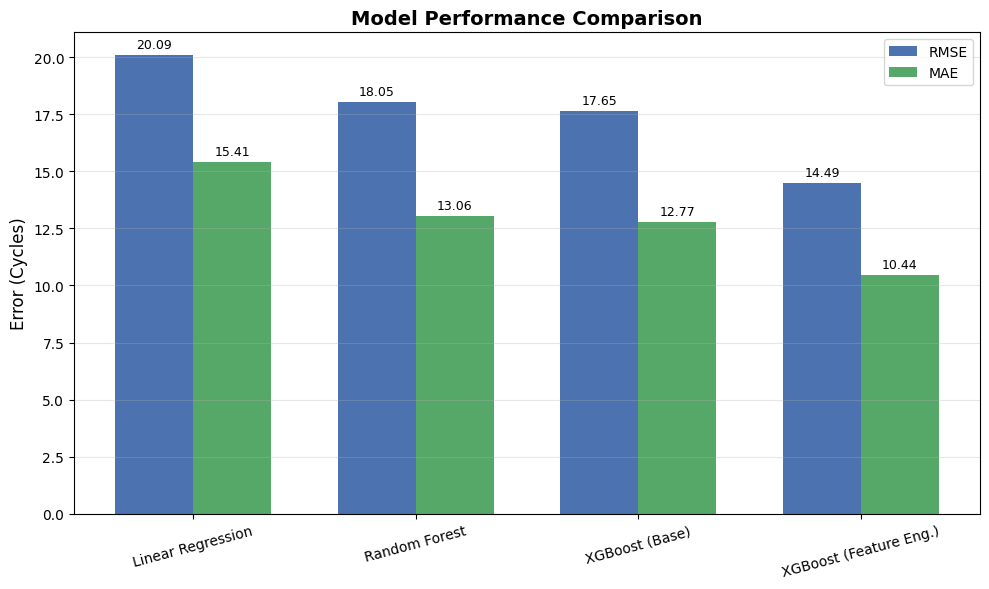

In [27]:
# RMSE and MAE values computed in the previous sections
models = ['Linear Regression', 'Random Forest', 'XGBoost (Base)', 'XGBoost (Feature Eng.)']
rmse_values = [rmse_lr, rmse_rf, rmse_xgb, rmse_xgb_fe]
mae_values = [mae_lr, mae_rf, mae_xgb, mae_xgb_fe]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, rmse_values, width, label='RMSE', color='#4C72B0')
bars2 = ax.bar(x + width/2, mae_values, width, label='MAE', color='#55A868')

ax.set_ylabel('Error (Cycles)', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add value labels on top of the bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, 
            f'{bar.get_height():.2f}', ha='center', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, 
            f'{bar.get_height():.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretation:** The error decreases in both metrics from linear regression to XGBoost with feature engineering. In RMSE, the improvement from feature engineering (about 3.16) is larger than the total improvement from changing the algorithm (from linear regression to XGBoost, about 2.44). In MAE the two contributions are close (about 2.33 versus 2.64).

### 6.2 Predicted vs. Actual Values (Final Model)

Each point is one test engine. The closer a point is to the dashed diagonal line, the more accurate the prediction.

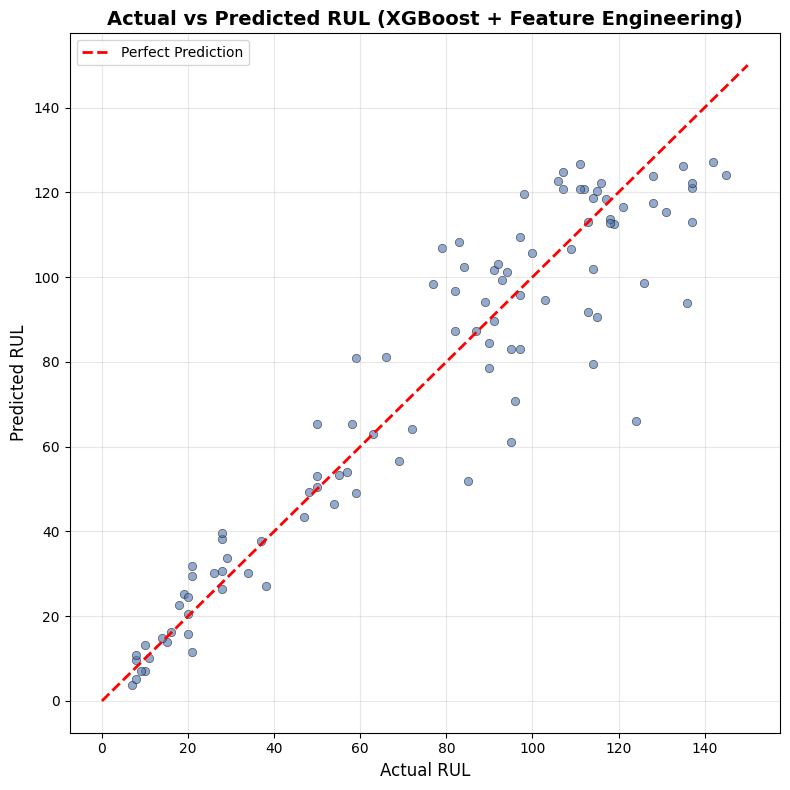

In [28]:
# Final model predictions (y_pred_xgb_fe) vs. actual RUL (rul_truth)
plt.figure(figsize=(8, 8))
plt.scatter(rul_truth, y_pred_xgb_fe, alpha=0.6, color='#4C72B0', edgecolors='black', linewidth=0.5)

# Ideal line (y = x)
max_val = max(rul_truth.max().values[0], y_pred_xgb_fe.max()) + 5
plt.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction')

plt.xlabel('Actual RUL', fontsize=12)
plt.ylabel('Predicted RUL', fontsize=12)
plt.title('Actual vs Predicted RUL (XGBoost + Feature Engineering)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** For engines close to failure (RUL below about 40), the predictions cluster around the diagonal, and the scatter is larger at high RUL values. Predictions saturate around 125 because the training labels were clipped at 125, while the true RUL of some test engines reaches about 145.

### 6.3 Effect of Feature Engineering on Prediction Quality

The previous plot is shown side by side for XGBoost without feature engineering (left) and with feature engineering (right).

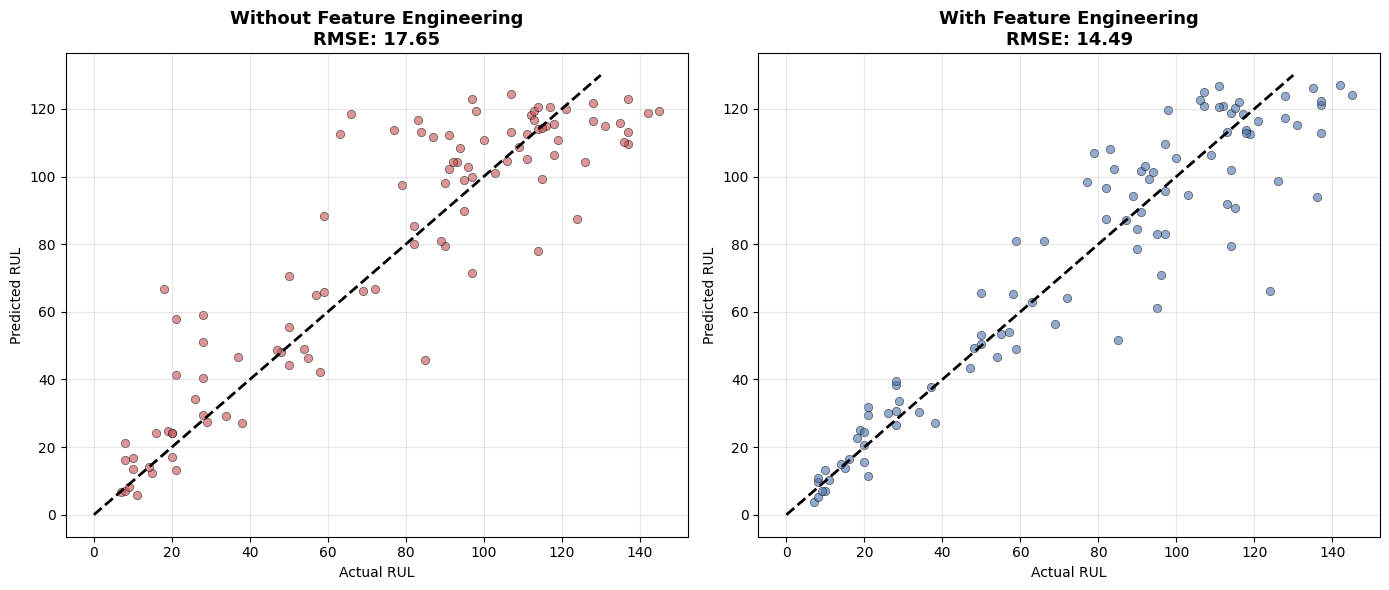

In [29]:
# Compare y_pred_xgb (without feature engineering) and y_pred_xgb_fe (with feature engineering)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Without FE
axes[0].scatter(rul_truth, y_pred_xgb, alpha=0.6, color='#C44E52', edgecolors='black', linewidth=0.5)
axes[0].plot([0, 130], [0, 130], 'k--', linewidth=2)
axes[0].set_title(f'Without Feature Engineering\nRMSE: {rmse_xgb:.2f}', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual RUL')
axes[0].set_ylabel('Predicted RUL')
axes[0].grid(alpha=0.3)

# With FE
axes[1].scatter(rul_truth, y_pred_xgb_fe, alpha=0.6, color='#4C72B0', edgecolors='black', linewidth=0.5)
axes[1].plot([0, 130], [0, 130], 'k--', linewidth=2)
axes[1].set_title(f'With Feature Engineering\nRMSE: {rmse_xgb_fe:.2f}', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Actual RUL')
axes[1].set_ylabel('Predicted RUL')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:** With feature engineering, the points move closer to the diagonal and RMSE goes from 17.65 to 14.49. The improvement is especially visible at low RUL values, which is where accuracy matters most in practice.

### 6.4 Feature Importance in the Final Model

The fifteen most important features in the final XGBoost:

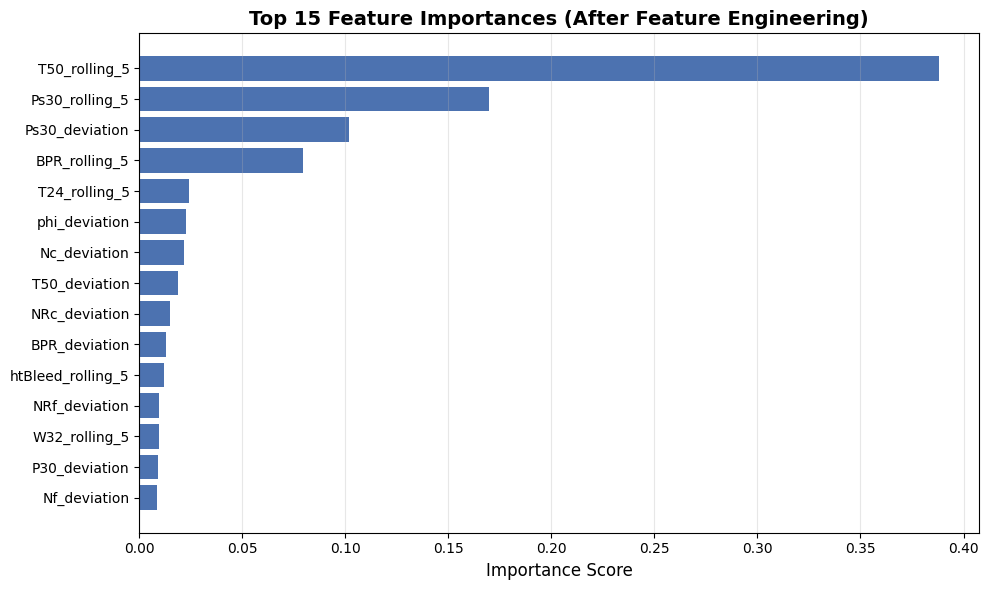

In [30]:
# Top 15 features of the final model
top15 = importance_fe.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top15['feature'][::-1], top15['importance'][::-1], color='#4C72B0')
plt.xlabel('Importance Score', fontsize=12)
plt.title('Top 15 Feature Importances (After Feature Engineering)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** All of the top ten features are engineered ones. At the top is `T50_rolling_5` with about 39%, followed by `Ps30_rolling_5` with about 17%, `Ps30_deviation` with about 10%, and `BPR_rolling_5` with about 8%. Among these ten, only moving averages and deviations from the initial state appear, and no `diff_10` feature is among them. Note that correlated features split the importance among themselves, so these numbers should be read as approximate.

### 6.5 Distribution of Prediction Errors

A histogram of "predicted − actual" for the 100 test engines. A negative value means the model underestimated the remaining life.

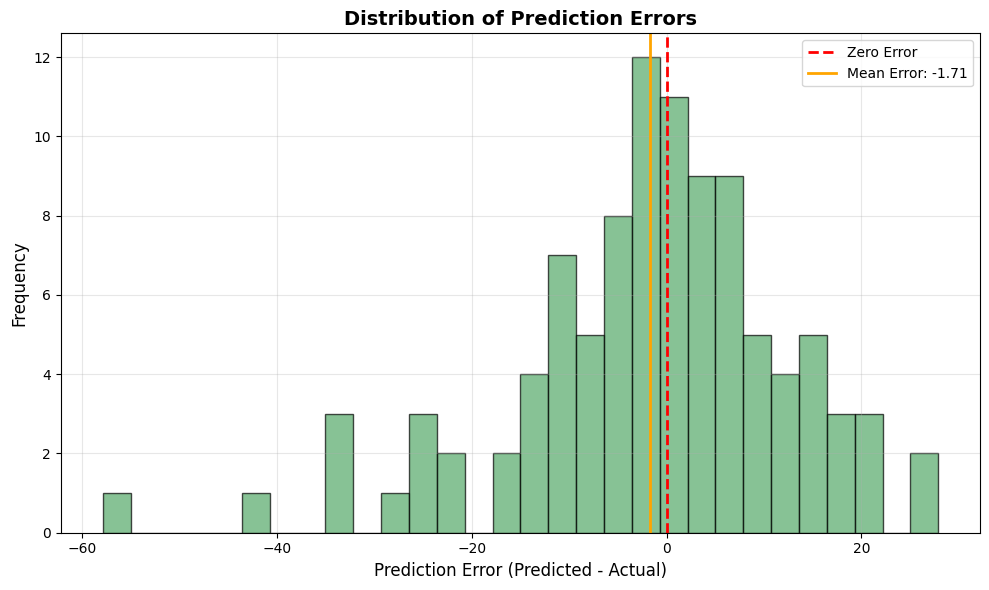

In [31]:
# Compute the errors
errors = np.array(y_pred_xgb_fe).flatten() - np.array(rul_truth).flatten()

plt.figure(figsize=(10, 6))
plt.hist(errors, bins=30, color='#55A868', edgecolor='black', alpha=0.7)
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero Error')
plt.axvline(x=errors.mean(), color='orange', linestyle='-', linewidth=2, label=f'Mean Error: {errors.mean():.2f}')

plt.xlabel('Prediction Error (Predicted - Actual)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Prediction Errors', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** Most errors cluster around zero, and the mean error is about -1.71, i.e. a small overall bias toward underestimation. The left tail of the distribution is longer (down to about -58, versus about +28 on the positive side). Underestimating RUL is usually safer than overestimating it, because maintenance is performed earlier rather than later.

## 7. Conclusion

### Summary of Results

| Model | Test RMSE | Test MAE | CV RMSE (mean ± std) |
|:---|:---:|:---:|:---:|
| Linear Regression (degree-2 polynomial) | 20.09 | 15.41 | 19.69 ± 1.29 |
| Random Forest | 18.05 | 13.06 | 18.62 ± 1.34 |
| XGBoost (Base) | 17.65 | 12.77 | 18.58 ± 1.42 |
| **XGBoost + Feature Engineering** | **14.49** | **10.44** | **12.70 ± 0.70** |

The cross-validation results confirm that the improvement from feature engineering is stable: the final model's CV RMSE is about 6 cycles lower than the best baseline model (18.58 → 12.70), with a smaller standard deviation.

- **Best model:** XGBoost with feature engineering. On the test data, the final model reached an **RMSE of 14.49** and an **MAE of 10.44**; that is, it is off by about 10 cycles on average.
- **Role of feature engineering:** This step reduced RMSE from 17.65 to 14.49 (about an 18% improvement) and MAE from 12.77 to 10.44 (about 18%). Compared with linear regression, RMSE is about 28% lower.
- **Effective features:** All ten top features of the final model were engineered ones, especially the moving averages of `T50` and `Ps30` and the deviation of `Ps30` from the initial state.
- **Error behavior:** Predictions are more accurate for engines close to failure. The model tends to underestimate (mean error about -1.71), and because of the RUL cap of 125, it predicts high values lower than the truth.

### Limitations and Future Work

**Limitations**

- The main evaluation was done on a single split; for added confidence, 5-fold GroupKFold results are also reported (Section 3.5).
- Hyperparameters were not tuned (commonly used values were applied).
- The RUL cap of 125 was applied to all models.

**Future work**

- Hyperparameter tuning.
- Building a combined Health Index from multiple sensors.
- Comparison with sequence models such as LSTM.